> **Decision recorded 2026-10-29 (before the H1 gate is opened; also in `dataset/analysis/DECISIONS.md`).**
> The main H1 analysis scores **every text in full**: chatbot answers whole, news articles whole (up to the 3,000-word corpus cap), with rarefied entropy (K = 5 frame hits, drawn without replacement, at least 500 repeats, fixed seed, averaged).
> **Robustness checks, not the main result:** topic-selected length-matched windows, a fixed 300-word cut, a fixed 150-word cut, K = 3 and 8, bounds, pooled counts, lexicon variants (no governance frame, no ambiguous terms, prompt-echo terms, no "lawsuit").
> The earlier team rule "cut every text to 300 words" is now only the "fixed 300" check.
> **Limitation to keep next to the result:** rarefaction fixes estimator bias, not real diversity. A longer article can genuinely cover more frames, which raises news entropy and works *against* H1.

# 05 – Rarefied entropy: H1 (main + robustness), H2, H3

**Why rarefaction.** Plain frame entropy depends on how many frame hits a text has: few hits give a low entropy by arithmetic, not by emphasis. Here every text is compared at the **same number of hits**: draw K frame hits at random *without replacement* from a text's hits, compute the normalised Shannon entropy (÷ log 6) of the K draws, repeat REPS times and average. K = 5 is the main setting; 3 and 8 are robustness checks. A text with fewer than K hits cannot be rarefied: it is excluded, and *how many* are excluded is reported. At K = 5 the maximum is log 5 / log 6 = 0.898, not 1, so compare groups at the same K only.

**The gate.** Sections 6 onward (everything that compares groups) need `H_TESTS_ENABLED = True`, which is allowed only because the lexicon is signed off (v1.2, `07_lexicon_signoff.ipynb` checks this). Sections 1–5 are measurement only.

**Clusters.** Answers to the same question are not independent (18 questions, 12 answers each over two chatbots), and neither are articles from one outlet. Intervals use a **cluster bootstrap**: `question_id` for chatbots, `outlet` for news. Difference = chatbot minus news; positive means the chatbot spreads emphasis more evenly (H1).

**Scoring.** Hits come from `03_frame_scoring.ipynb` section 9 (`term_hits_full.csv`, lexicon v1.2): the same scorer for every text, no word cut. Lexicon variants are built by dropping terms from those counts.

In [1]:
import json, re, bisect
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr, ks_2samp

from framescore import Lexicon, find_hits, count_vector, entropy, rarefied_entropy, MAX_WORDS, cut

H_TESTS_ENABLED = True       # opened 2026-10-29: lexicon v1.2 is signed off (07_lexicon_signoff.ipynb checks that a gate is open only if so)
SEED, REPS, N_BOOT = 42, 1000, 5000
KS, MAIN_K = (3, 5, 8), 5

CFG = json.load(open("config.json"))
OUT = Path(CFG["analysis_dir"]); OUT.mkdir(parents=True, exist_ok=True)
LEX = Lexicon(CFG["lexicon_json"]); FRAMES = LEX.frames; HC = [f"hits_{f}" for f in FRAMES]
MODELS = {"Llama": "llama3.1:8b", "Qwen": "qwen3.5:9b"}
COLOR = {"Llama": "#2a78d6", "Qwen": "#eb6834", "news": "#1baf7a"}
assert json.load(open(CFG["lexicon_json"]))["signed_off"], "the lexicon is not signed off"
print("lexicon", LEX.version, "| H tests enabled:", H_TESTS_ENABLED, "| reps", REPS, "| seed", SEED)

lexicon 1.2 | H tests enabled: True | reps 1000 | seed 42


## 1. Load the full-text scores

In [2]:
chat = pd.read_csv(OUT / "frame_scores_chatbot_full.csv")
chat["group"] = chat["chatbot"].map({v: k for k, v in MODELS.items()}); chat["cluster"] = chat["question_id"]
chat["text_id"] = chat["prompt_id"] + "|" + chat["chatbot"] + "|" + chat["replicate"].astype(str)
news = pd.read_csv(OUT / "frame_scores_news_full.csv")
news["group"] = "news"; news["cluster"] = news["outlet"]; news["text_id"] = news["doc_id"]
term = pd.read_csv(OUT / "term_hits_full.csv")
term["pid"] = np.where(term["source"] == "chatbot", term["text_id"].str.split("|").str[0], "")
assert not (set(term["term"]) & set(LEX.jur_owner)), "jurisdiction terms must not be in the frame counts"
print(len(chat), "answers |", len(news), "articles |", chat["cluster"].nunique(), "question clusters |", news["cluster"].nunique(), "outlet clusters")
print("jurisdiction terms are kept out of the frame counts (checked).")

216 answers | 420 articles | 18 question clusters | 285 outlet clusters
jurisdiction terms are kept out of the frame counts (checked).


## 2. Lengths (full text)
Chatbot answers are 176–359 words; articles are whole (the corpus cap is 3,000 words). The length gap is large, which is exactly why entropy is compared at equal hit counts and why the length-matched windows are a robustness check.

In [3]:
def wstats(d, name):
    w = d["n_words"]; return {"group": name, "n_texts": len(d), "words_mean": w.mean(), "words_median": w.median(), "words_min": w.min(), "words_max": w.max()}
length_full = pd.DataFrame([wstats(chat[chat.group == "Llama"], "Llama"), wstats(chat[chat.group == "Qwen"], "Qwen"), wstats(chat, "chatbots pooled"), wstats(news, "news")] +
                           [wstats(news[news.region == r], f"news | {r}") for r in ["US", "UK", "EU", "Other"]]).round(1)
length_full.to_csv(OUT / "length_full_text.csv", index=False)
display(length_full)

,group,n_texts,words_mean,words_median,words_min,words_max
0,Llama,108,223.2,224.0,176,263
1,Qwen,108,294.8,288.0,257,359
2,chatbots pooled,216,259.0,259.0,176,359
3,news,420,1042.8,928.5,173,2949
4,news | US,133,1119.9,986.0,177,2949
5,news | UK,101,939.2,847.0,173,2356
6,news | EU,82,1128.5,1090.5,281,2844
7,news | Other,104,977.2,832.5,325,2653


## 3. Frame density (a result in its own right)
Share of texts with fewer than K hits per group (the texts rarefaction must exclude), and hits per 100 words as a descriptive table.

In [4]:
rows = []
parts = {"Llama": chat[chat.group == "Llama"], "Qwen": chat[chat.group == "Qwen"], "chatbots pooled": chat, "news": news,
         **{f"news | {r}": news[news.region == r] for r in ["US", "UK", "EU", "Other"]}}
for nm, g in parts.items():
    rows.append({"group": nm, "n_texts": len(g), **{f"share_under_{k}_hits": (g["hits_total"] < k).mean() for k in KS},
                 "n_under_5": int((g["hits_total"] < 5).sum()), "hits_mean": g["hits_total"].mean(), "hits_median": g["hits_total"].median(),
                 "hits_per_100w_mean": g["hits_per_100w"].mean(), "hits_per_100w_median": g["hits_per_100w"].median()})
density = pd.DataFrame(rows).round(3); density.to_csv(OUT / "frame_density_full_text.csv", index=False)
display(density)

,group,n_texts,share_under_3_hits,share_under_5_hits,share_under_8_hits,n_under_5,hits_mean,hits_median,hits_per_100w_mean,hits_per_100w_median
0,Llama,108,0.000,0.000,0.046,0,15.833,16.0,7.074,6.920
1,Qwen,108,0.000,0.000,0.000,0,27.620,28.0,9.374,9.645
2,chatbots pooled,216,0.000,0.000,0.023,0,21.727,21.0,8.224,8.329
3,news,420,0.010,0.017,0.057,7,30.221,25.0,3.020,2.853
4,news | US,133,0.008,0.008,0.038,1,31.782,26.0,2.921,2.837
5,news | UK,101,0.010,0.020,0.079,2,28.861,24.0,3.222,2.935
6,news | EU,82,0.012,0.024,0.037,2,32.622,27.0,3.108,3.188
7,news | Other,104,0.010,0.019,0.077,2,27.654,21.0,2.879,2.542


## 4. Rarefied entropy per text (main: full text, K = 5)
Vectors are built from the term-level counts, so every lexicon variant uses the same machinery. One row per text and K; saved without text.

In [5]:
AMB = LEX.ambiguous
prompts = pd.read_csv(CFG["prompts_csv"])
prompt_hits = find_hits(prompts["prompt"], LEX.matcher, LEX.owner)
echo_own = {pid: {l for _, l in h} for pid, h in zip(prompts["prompt_id"], prompt_hits)}      # terms in an answer's own prompt
echo_all = set().union(*echo_own.values())                                                   # terms in any prompt
own_pairs = {(pid, t) for pid, ts in echo_own.items() for t in ts}
print(len(AMB), "ambiguous terms |", len(echo_all), "lexicon terms occur in some prompt")

def mat(df, source, frames=FRAMES, drop_terms=frozenset(), drop_pairs=None):
    t = term[term["source"] == source]
    if drop_terms: t = t[~t["term"].isin(drop_terms)]
    if drop_pairs is not None: t = t[[(p, x) not in drop_pairs for p, x in zip(t["pid"], t["term"])]]
    t = t[t["frame"].isin(frames)]
    m = t.pivot_table(index="text_id", columns="frame", values="n", aggfunc="sum", fill_value=0)
    return m.reindex(index=df["text_id"], columns=list(frames), fill_value=0).to_numpy(int)

def rar(M, k, reps=REPS):
    r = np.random.default_rng(SEED + k)
    return np.array([rarefied_entropy(row, k, r, reps) for row in M])

M_chat, M_news = mat(chat, "chatbot"), mat(news, "news")
assert (M_chat == chat[HC].to_numpy()).all() and (M_news == news[HC].to_numpy()).all(), "term counts disagree with the frame counts"
for k in KS:
    chat[f"rar{k}"] = rar(M_chat, k); news[f"rar{k}"] = rar(M_news, k)
chat["plugin5"] = [entropy(r, 5) for r in M_chat]; news["plugin5"] = [entropy(r, 5) for r in M_news]
keep = ["text_id", "group", "cluster", "n_words", "hits_total", "hits_per_100w", "plugin5"] + [f"rar{k}" for k in KS]
pd.concat([chat[keep + ["wording", "topic_frame"]], news[keep + ["region"]]]).assign(view=lambda d: np.where(d.group == "news", "news (full text)", d.group + " (full text)")) \
  .to_csv(OUT / "rarefied_entropy_per_text.csv", index=False)
print("texts scored at K=5:", {g: int(d["rar5"].notna().sum()) for g, d in [("chatbot", chat), ("news", news)]}, "(counts only; group means are H1 results)")

28 ambiguous terms | 14 lexicon terms occur in some prompt


texts scored at K=5: {'chatbot': 216, 'news': 413} (counts only; group means are H1 results)


## 5. Does entropy still depend on length and hit count?
Spearman correlation of entropy with word count and with hit count, **before** rarefaction (plain entropy, texts with at least 5 hits) and **after** (rarefied, K = 5). After rarefaction the correlation with hit count should be close to zero by construction. The one with word count shows whether anything length-related is left.

In [6]:
rows = []
pools = {"chatbots pooled": chat, "Llama": chat[chat.group == "Llama"], "Qwen": chat[chat.group == "Qwen"], "news": news}
for name, d in pools.items():
    for col, label in [("plugin5", "before (plain entropy)"), ("rar5", "after (rarefied, K=5)")]:
        ok = d.dropna(subset=[col])
        for x, xl in [("n_words", "word count"), ("hits_total", "hit count")]:
            rho, p = spearmanr(ok[x], ok[col]); rows.append({"texts": name, "entropy": label, "against": xl, "n": len(ok), "spearman_rho": round(rho, 3)})
corr = pd.DataFrame(rows); corr.to_csv(OUT / "entropy_length_correlations_full_text.csv", index=False)
display(corr.pivot_table(index=["texts", "against"], columns="entropy", values="spearman_rho"))

entropy                     after (rarefied, K=5)  before (plain entropy)
texts           against                                                  
Llama           hit count                  -0.166                   0.033
                word count                 -0.017                   0.031
Qwen            hit count                  -0.036                   0.145
                word count                 -0.103                  -0.078
chatbots pooled hit count                   0.200                   0.485
                word count                  0.293                   0.495
news            hit count                  -0.073                   0.213
                word count                  0.052                   0.209

**Reading the correlations.** Before rarefaction plain entropy tracks length and hit count (pooled chatbots ρ = 0.50 with words, 0.49 with hits; news 0.21 with both). After rarefaction the within-group correlations are near zero (Llama −0.02 with words, −0.17 with hits; Qwen −0.10 and −0.04; news +0.05 and −0.07). The pooled-chatbot figures after rarefaction (0.29 with words, 0.20 with hits) come from pooling two models that differ in both length and entropy (Qwen is longer and higher); within each model the dependence is gone.

## 6. H1 machinery
`compare` takes the per-text scores of the two groups and returns the difference in mean rarefied entropy (chatbot minus news) with a 95% cluster-bootstrap interval. `SUMMARY` collects one line per run for the final table.

In [7]:
assert H_TESTS_ENABLED, "gate closed: sections 6 onward compare groups"

def boot_means(values, clusters, n_boot=N_BOOT, seed=SEED):
    v = pd.Series(np.asarray(values, float)); c = pd.Series(np.asarray(clusters))
    g = v.groupby(c.values); sums, cnts = g.sum().to_numpy(), g.count().to_numpy()
    idx = np.random.default_rng(seed).integers(0, len(sums), (n_boot, len(sums)))
    return v.mean(), sums[idx].sum(axis=1) / np.maximum(cnts[idx].sum(axis=1), 1)

def compare(va, ca, vb, cb, n_boot=N_BOOT):
    ma, ba = boot_means(va, ca, n_boot, SEED); mb, bb = boot_means(vb, cb, n_boot, SEED + 1)
    d = ba - bb; lo, hi = np.percentile(d, [2.5, 97.5])
    return {"n_chatbot": int(np.isfinite(va).sum()), "n_news": int(np.isfinite(vb).sum()), "chatbot_mean": ma, "news_mean": mb,
            "diff": ma - mb, "diff_lo": lo, "diff_hi": hi, "excludes_zero": bool(lo > 0 or hi < 0),
            "direction": "chatbot higher" if ma > mb else "news higher"}

GROUPS = {"Llama": lambda d: d[d.group == "Llama"], "Qwen": lambda d: d[d.group == "Qwen"], "chatbots pooled": lambda d: d}
SUMMARY = []
def run_rows(run, col, chat_df, news_df, extra=None):
    rows = []
    for gname, sel in GROUPS.items():
        a = sel(chat_df)
        r = compare(a[col].to_numpy(float), a["cluster"].to_numpy(), news_df[col].to_numpy(float), news_df["cluster"].to_numpy())
        rows.append({"run": run, "comparison": f"{gname} vs news", **(extra or {}), **r})
    df = pd.DataFrame(rows); SUMMARY.extend(df.to_dict("records")); return df

## 7. Main H1 result: full text, K = 5

In [8]:
main = run_rows("main: full text, K=5", "rar5", chat, news)
share = {"Llama": (chat[chat.group == "Llama"].hits_total < 5).mean(), "Qwen": (chat[chat.group == "Qwen"].hits_total < 5).mean(),
         "chatbots pooled": (chat.hits_total < 5).mean()}
main["share_chatbot_under_5_hits"] = main["comparison"].map(lambda c: share[c.split(" vs")[0]]); main["share_news_under_5_hits"] = (news.hits_total < 5).mean()
main.round(4).to_csv(OUT / "h1_main.csv", index=False)
display(main.drop(columns=["run"]).round(4))

,comparison,n_chatbot,n_news,chatbot_mean,news_mean,diff,diff_lo,diff_hi,excludes_zero,direction,share_chatbot_under_5_hits,share_news_under_5_hits
0,Llama vs news,108,413,0.4931,0.4969,-0.0037,-0.0349,0.0266,False,news higher,0.0,0.0167
1,Qwen vs news,108,413,0.5547,0.4969,0.0579,0.0372,0.0778,True,chatbot higher,0.0,0.0167
2,chatbots pooled vs news,216,413,0.5239,0.4969,0.0271,0.0022,0.0507,True,chatbot higher,0.0,0.0167


> **Limitation, next to the result.** Rarefaction fixes the *estimator's* dependence on the number of hits; it does not fix *real* diversity. A longer article can genuinely cover more frames than a 250-word answer, which would raise news entropy and so works *against* H1 (a positive chatbot-minus-news difference would then be found despite the length advantage of news, not because of an artefact). Conversely, because news is scored whole, any chatbot-minus-news difference that is negative or near zero may reflect the extra room articles have, not a narrower emphasis. The length-matched windows (section 11) and the fixed cuts (section 10) are the checks on this.

## 8. Sensitivity to the draw size, bounds, pooled counts

In [9]:
sens = pd.concat([run_rows(f"K={k}", f"rar{k}", chat, news, {"K": k}) for k in (3, 8)], ignore_index=True)
sens.round(4).to_csv(OUT / "h1_sensitivity_k.csv", index=False); display(sens.drop(columns=["run"]).round(4))

,comparison,K,n_chatbot,n_news,chatbot_mean,news_mean,diff,diff_lo,diff_hi,excludes_zero,direction
0,Llama vs news,3,108,416,0.3773,0.3775,-0.0002,-0.0229,0.0216,False,news higher
1,Qwen vs news,3,108,416,0.4192,0.3775,0.0416,0.0273,0.0556,True,chatbot higher
2,chatbots pooled vs news,3,216,416,0.3983,0.3775,0.0207,0.0031,0.0374,True,chatbot higher
3,Llama vs news,8,103,396,0.5660,0.5771,-0.0112,-0.0480,0.0251,False,news higher
4,Qwen vs news,8,108,396,0.6437,0.5771,0.0665,0.0414,0.0905,True,chatbot higher
5,chatbots pooled vs news,8,211,396,0.6057,0.5771,0.0286,-0.0003,0.0562,False,chatbot higher


In [10]:
# Bounds: texts with fewer than K hits cannot be rarefied. Put them back with an assumed score: (a) the minimum possible entropy (0),
# (b) the median of the scored texts in the same group, (c) the maximum possible, log K / log 6 (the adversarial case).
rows = []
for rule, fill in [("(a) excluded scored at the minimum (0)", lambda d, k: 0.0),
                   ("(b) excluded scored at the group median", lambda d, k: d["rar5"].median()),
                   ("(c) excluded scored at the maximum", lambda d, k: np.log(k) / np.log(len(FRAMES)))]:
    c2, n2 = chat.copy(), news.copy()
    for d in (c2, n2):
        for g in d["group"].unique():
            m = (d["group"] == g) & d["rar5"].isna(); d.loc[m, "rar5"] = fill(d[d["group"] == g], 5)
    rows.append(run_rows("bounds: " + rule, "rar5", c2, n2, {"rule": rule}))
bounds_df = pd.concat(rows, ignore_index=True); bounds_df.round(4).to_csv(OUT / "h1_bounds.csv", index=False)
print("excluded at K=5: chatbot", int(chat.rar5.isna().sum()), "| news", int(news.rar5.isna().sum()))
display(bounds_df.drop(columns=["run"]).round(4))

excluded at K=5: chatbot 0 | news 7


,comparison,rule,n_chatbot,n_news,chatbot_mean,news_mean,diff,diff_lo,diff_hi,excludes_zero,direction
0,Llama vs news,(a) excluded scored at the minimum (0),108,420,0.4931,0.4886,0.0046,-0.0276,0.0362,False,chatbot higher
1,Qwen vs news,(a) excluded scored at the minimum (0),108,420,0.5547,0.4886,0.0662,0.0445,0.0872,True,chatbot higher
2,chatbots pooled vs news,(a) excluded scored at the minimum (0),216,420,0.5239,0.4886,0.0354,0.0099,0.0599,True,chatbot higher
3,Llama vs news,(b) excluded scored at the group median,108,420,0.4931,0.4971,-0.0040,-0.0351,0.0263,False,news higher
4,Qwen vs news,(b) excluded scored at the group median,108,420,0.5547,0.4971,0.0576,0.0370,0.0774,True,chatbot higher
5,chatbots pooled vs news,(b) excluded scored at the group median,216,420,0.5239,0.4971,0.0268,0.0022,0.0503,True,chatbot higher
6,Llama vs news,(c) excluded scored at the maximum,108,420,0.4931,0.5035,-0.0104,-0.0419,0.0202,False,news higher
7,Qwen vs news,(c) excluded scored at the maximum,108,420,0.5547,0.5035,0.0512,0.0304,0.0715,True,chatbot higher
8,chatbots pooled vs news,(c) excluded scored at the maximum,216,420,0.5239,0.5035,0.0204,-0.0046,0.0441,False,chatbot higher


In [11]:
# Pooled: add up the hits of every text in a group, draw N hits from the pooled counts (N = the smaller pooled total), compare groups.
def pooled_compare(Ma, ca, Mb, cb, reps=REPS, n_boot=500, seed=SEED):
    r = np.random.default_rng(seed); ta, tb = Ma.sum(axis=0), Mb.sum(axis=0); N = int(min(ta.sum(), tb.sum()))
    ea, eb = rarefied_entropy(ta, N, r, reps), rarefied_entropy(tb, N, r, reps)
    CA = pd.DataFrame(Ma).groupby(np.asarray(ca)).sum().to_numpy(); CB = pd.DataFrame(Mb).groupby(np.asarray(cb)).sum().to_numpy()
    boots = []
    for _ in range(n_boot):
        pa = CA[r.integers(0, len(CA), len(CA))].sum(axis=0); pb = CB[r.integers(0, len(CB), len(CB))].sum(axis=0)
        n = int(min(N, pa.sum(), pb.sum())); boots.append(rarefied_entropy(pa, n, r, 50) - rarefied_entropy(pb, n, r, 50))
    lo, hi = np.percentile(boots, [2.5, 97.5]); est = ea - eb
    # Resampling few clusters (18 questions) concentrates a pooled mix, so the bootstrap differences sit below the estimate.
    # boot_mean_diff shows that shift; the "basic" interval (2*est - upper, 2*est - lower) corrects for it.
    return {"N_hits_drawn": N, "chatbot_pooled_entropy": ea, "news_pooled_entropy": eb, "diff": est, "diff_lo": lo, "diff_hi": hi,
            "excludes_zero": bool(lo > 0 or hi < 0), "direction": "chatbot higher" if ea > eb else "news higher",
            "boot_mean_diff": float(np.mean(boots)), "diff_lo_basic": 2 * est - hi, "diff_hi_basic": 2 * est - lo,
            "basic_excludes_zero": bool(2 * est - hi > 0 or 2 * est - lo < 0)}

rows = []
for gname, sel in GROUPS.items():
    a = sel(chat); Ma = M_chat[a.index]
    rows.append({"run": "pooled counts", "comparison": f"{gname} vs news", **pooled_compare(Ma, a["cluster"], M_news, news["cluster"])})
pooled_df = pd.DataFrame(rows); SUMMARY.extend(pooled_df.to_dict("records"))
pooled_df.round(4).to_csv(OUT / "h1_pooled.csv", index=False); display(pooled_df.drop(columns=["run"]).round(4))

,comparison,N_hits_drawn,chatbot_pooled_entropy,news_pooled_entropy,diff,diff_lo,diff_hi,excludes_zero,direction,boot_mean_diff,diff_lo_basic,diff_hi_basic,basic_excludes_zero
0,Llama vs news,1710,0.9441,0.9345,0.0096,-0.0725,0.0434,False,chatbot higher,-0.0073,-0.0242,0.0917,False
1,Qwen vs news,2983,0.9101,0.9348,-0.0247,-0.0720,0.0127,False,news higher,-0.0289,-0.0620,0.0227,False
2,chatbots pooled vs news,4693,0.9251,0.9350,-0.0100,-0.0686,0.0257,False,news higher,-0.0191,-0.0456,0.0487,False


**Reading the pooled run.** The point estimates are small and of mixed sign (Llama +0.010, Qwen −0.025, pooled −0.010) and every interval includes zero. The percentile bootstrap is shifted below the estimate (bootstrap mean differences −0.007, −0.029, −0.019): resampling 18 question clusters concentrates the chatbot mix. The bias-corrected "basic" interval (columns `diff_lo_basic`, `diff_hi_basic`) also includes zero in all three, so the conclusion does not depend on the interval method.

## 9. Lexicon variants (K = 5, full text)
Each variant drops terms from the term-level counts and rarefies again. *No governance:* the governance frame is removed and entropy is normalised by log 5 (the topic itself is regulation, so that frame may sit near its ceiling in every text). *No ambiguous terms:* the 28 ambiguous terms are dropped. *Prompt-echo (own prompt):* each answer loses the terms found in its own prompt (chatbots only, as in notebook 03). *Prompt-echo (all prompts):* every term found in any of the 54 prompts is dropped from **both** groups, which is the symmetric version. *No lawsuit:* the single term "lawsuit" is dropped (it fires in 6 of 216 answers but in 52 of 420 articles).

In [12]:
def variant(run, frames=FRAMES, drop_terms=frozenset(), own=False):
    Mc = mat(chat, "chatbot", frames, drop_terms, own_pairs if own else None); Mn = mat(news, "news", frames, drop_terms)
    c2, n2 = chat.copy(), news.copy(); c2["v"], n2["v"] = rar(Mc, MAIN_K), rar(Mn, MAIN_K)
    out = run_rows(run, "v", c2, n2)
    out["excluded_chatbot"] = int(c2["v"].isna().sum()); out["excluded_news"] = int(n2["v"].isna().sum()); return out

noext = [f for f in FRAMES if f != "regulation_governance"]
lex_runs = pd.concat([
    variant("lexicon: no governance frame", frames=noext),
    variant("lexicon: no ambiguous terms", drop_terms=AMB),
    variant("lexicon: no prompt-echo terms (own prompt, chatbots only)", own=True),
    variant("lexicon: no prompt-echo terms (all prompt terms, both groups)", drop_terms=echo_all),
    variant("lexicon: no 'lawsuit'", drop_terms={"lawsuit"}),
    variant("lexicon: all terms (reference, = main)")], ignore_index=True)
lex_runs.round(4).to_csv(OUT / "h1_lexicon_variants.csv", index=False)
display(lex_runs.drop(columns=["run"]).round(4).assign(run=lex_runs["run"].str.replace("lexicon: ", "")).set_index("run"))

,comparison,n_chatbot,n_news,chatbot_mean,news_mean,diff,diff_lo,diff_hi,excludes_zero,direction,excluded_chatbot,excluded_news
run,,,,,,,,,,,,
no governance frame,Llama vs news,103,399,0.4449,0.4673,-0.0224,-0.0604,0.0158,False,news higher,5,21
no governance frame,Qwen vs news,108,399,0.5424,0.4673,0.0751,0.0417,0.1069,True,chatbot higher,5,21
no governance frame,chatbots pooled vs news,211,399,0.4948,0.4673,0.0275,-0.0062,0.0611,False,chatbot higher,5,21
no ambiguous terms,Llama vs news,103,393,0.4543,0.4818,-0.0274,-0.0762,0.0204,False,news higher,5,27
no ambiguous terms,Qwen vs news,108,393,0.5443,0.4818,0.0625,0.0358,0.0878,True,chatbot higher,5,27
no ambiguous terms,chatbots pooled vs news,211,393,0.5004,0.4818,0.0186,-0.0173,0.0533,False,chatbot higher,5,27
"no prompt-echo terms (own prompt, chatbots only)",Llama vs news,107,413,0.5301,0.4969,0.0332,0.0073,0.0585,True,chatbot higher,1,7
"no prompt-echo terms (own prompt, chatbots only)",Qwen vs news,108,413,0.5595,0.4969,0.0627,0.0425,0.0810,True,chatbot higher,1,7
"no prompt-echo terms (own prompt, chatbots only)",chatbots pooled vs news,215,413,0.5449,0.4969,0.0480,0.0265,0.0682,True,chatbot higher,1,7


## 10. Fixed cuts: first 300 words and first 150 words
Both groups are cut to the first N words and re-scored with the same scorer. For each cut the table reports how many texts are still **on-topic** (at least 2 AI words and 2 regulation words, the corpus rule) and **scorable** (at least 5 hits), because a short cut drops hits.

In [13]:
AI_WORDS  = re.compile(r"\b(AI|artificial intelligence|chatbots?|ChatGPT|large language models?|LLMs?|OpenAI|Gemini)\b")
REG_WORDS = re.compile(r"\b(regulat\w*|legislat\w*|laws?|AI Act|bills?|rules?|oversight|ban|governance|policy|lawmakers?)\b", re.I)
ans_raw = pd.read_json(CFG["answers_jsonl"], lines=True); ans_raw = ans_raw[ans_raw.chatbot.isin(MODELS.values())].reset_index(drop=True)
ans_raw["text_id"] = ans_raw["prompt_id"] + "|" + ans_raw["chatbot"] + "|" + ans_raw["replicate"].astype(str)
raw_chat = ans_raw.set_index("text_id").loc[chat["text_id"], "answer"].tolist()
news_raw = pd.read_csv(CFG["news_corpus_csv"], keep_default_na=False)
assert news_raw["doc_id"].tolist() == news["doc_id"].tolist()
raw_news = news_raw["text"].tolist()

def topic_flags(texts):
    ai = np.array([len(AI_WORDS.findall(t)) for t in texts]); rg = np.array([len(REG_WORDS.findall(t)) for t in texts]); return (ai >= 2) & (rg >= 2)

def score_texts(texts):
    return np.array([count_vector(h, FRAMES) for h in find_hits(texts, LEX.matcher, LEX.owner)], int)

cut_runs, cut_share = [], []
for n in (300, 150):
    tc, tn = [cut(t, n) for t in raw_chat], [cut(t, n) for t in raw_news]
    Mc, Mn = score_texts(tc), score_texts(tn)
    c2, n2 = chat.copy(), news.copy(); c2["v"], n2["v"] = rar(Mc, MAIN_K), rar(Mn, MAIN_K)
    c2["n_words_cut"] = [min(len(t.split()), n) for t in raw_chat]; n2["n_words_cut"] = [min(len(t.split()), n) for t in raw_news]
    oc, on = topic_flags(tc), topic_flags(tn)
    for nm, d, M, o in [("Llama", c2[c2.group == "Llama"], Mc[(c2.group == "Llama").to_numpy()], oc[(c2.group == "Llama").to_numpy()]),
                        ("Qwen", c2[c2.group == "Qwen"], Mc[(c2.group == "Qwen").to_numpy()], oc[(c2.group == "Qwen").to_numpy()]),
                        ("news", n2, Mn, on)] + [(f"news | {r}", n2[n2.region == r], Mn[(n2.region == r).to_numpy()], on[(n2.region == r).to_numpy()]) for r in ["US", "UK", "EU", "Other"]]:
        cut_share.append({"cut": f"first {n} words", "group": nm, "n_texts": len(d), "words_median": d["n_words_cut"].median(), "share_on_topic_in_cut": o.mean(),
                          "share_scorable_5_hits": (M.sum(axis=1) >= 5).mean(), "hits_mean": M.sum(axis=1).mean()})
    cut_runs.append(run_rows(f"fixed cut: first {n} words", "v", c2, n2, {"cut_words": n}))
cut_df = pd.concat(cut_runs, ignore_index=True); cut_df.round(4).to_csv(OUT / "h1_fixed_cuts.csv", index=False)
cut_shares = pd.DataFrame(cut_share).round(3); cut_shares.to_csv(OUT / "h1_cut_shares.csv", index=False)
display(cut_shares); display(cut_df.drop(columns=["run"]).round(4))

,cut,group,n_texts,words_median,share_on_topic_in_cut,share_scorable_5_hits,hits_mean
0,first 300 words,Llama,108,224.0,0.556,1.000,15.833
1,first 300 words,Qwen,108,288.0,0.806,1.000,26.889
2,first 300 words,news,420,300.0,0.374,0.764,8.557
3,first 300 words,news | US,133,300.0,0.361,0.774,8.511
4,first 300 words,news | UK,101,300.0,0.426,0.822,9.079
5,first 300 words,news | EU,82,300.0,0.354,0.780,8.829
6,first 300 words,news | Other,104,300.0,0.356,0.683,7.894
7,first 150 words,Llama,108,150.0,0.398,0.963,10.083
8,first 150 words,Qwen,108,150.0,0.509,0.991,13.861
9,first 150 words,news,420,150.0,0.210,0.405,4.364


,comparison,cut_words,n_chatbot,n_news,chatbot_mean,news_mean,diff,diff_lo,diff_hi,excludes_zero,direction
0,Llama vs news,300,108,321,0.4931,0.4548,0.0383,0.0046,0.0718,True,chatbot higher
1,Qwen vs news,300,108,321,0.5550,0.4548,0.1002,0.0748,0.1247,True,chatbot higher
2,chatbots pooled vs news,300,216,321,0.5241,0.4548,0.0693,0.0412,0.0966,True,chatbot higher
3,Llama vs news,150,104,170,0.4862,0.4467,0.0394,-0.0046,0.0825,False,chatbot higher
4,Qwen vs news,150,107,170,0.5474,0.4467,0.1006,0.0615,0.1379,True,chatbot higher
5,chatbots pooled vs news,150,211,170,0.5172,0.4467,0.0705,0.0307,0.1090,True,chatbot higher


## 11. Topic-selected, length-matched windows
For each article and each target (the model's own answer-length distribution; one target length per article per model, drawn with replacement, seeded) the window of that length with the **most AI-word plus regulation-word matches that still passes the on-topic rule** (at least 2 of each, inside the window) is chosen; then up to 3 non-overlapping windows per article. An article shorter than its target keeps all its words (one window). Windows are re-scored with the same scorer and compared with the chatbot's whole answers; the bootstrap clusters by outlet. A third set is matched to the pooled answer-length distribution for the pooled comparison. Articles with no window that passes the rule drop out, and the table says how many.

In [14]:
def word_counts(text, rx):
    starts = [m.start() for m in re.finditer(r"\S+", text)]; c = np.zeros(len(starts) + 1)
    for m in rx.finditer(text):
        c[bisect.bisect_right(starts, m.start()) - 1 + 1] += 1
    return np.cumsum(c), starts

def pick_windows(text, L, max_windows=3):
    words = text.split(); n = len(words); L = min(L, n)
    ca, _ = word_counts(text, AI_WORDS); cr, _ = word_counts(text, REG_WORDS)
    s = np.arange(0, n - L + 1); ai = ca[s + L] - ca[s]; rg = cr[s + L] - cr[s]
    ok = (ai >= 2) & (rg >= 2); score = np.where(ok, ai + rg, -1); out = []
    for _ in range(max_windows):
        if score.max() < 0: break
        j = int(score.argmax()); out.append((j, j + L)); score[max(0, j - L + 1): j + L] = -1       # block every overlapping start
    return [" ".join(words[a:b]) for a, b in out]

def windows_for(lengths, seed=SEED):
    target = np.random.default_rng(seed).choice(lengths, size=len(raw_news), replace=True)
    rows, texts = [], []
    for i, (t, L) in enumerate(zip(raw_news, target)):
        for k, w in enumerate(pick_windows(t, int(L))):
            rows.append({"doc_id": news.doc_id[i], "outlet": news.outlet[i], "region": news.region[i], "window": k + 1, "target": int(L), "n_words": len(w.split())}); texts.append(w)
    df = pd.DataFrame(rows); M = score_texts(texts)
    df["cluster"] = df["outlet"]; df["text_id"] = df["doc_id"] + "#" + df["window"].astype(str); df["group"] = "news"
    df["rar5"] = rar(M, MAIN_K); df["hits_total"] = M.sum(axis=1)
    return df

len_llama = chat.loc[chat.group == "Llama", "n_words"].to_numpy(); len_qwen = chat.loc[chat.group == "Qwen", "n_words"].to_numpy(); len_all = chat["n_words"].to_numpy()
WIN = {"Llama": windows_for(len_llama), "Qwen": windows_for(len_qwen, SEED + 1), "chatbots pooled": windows_for(len_all, SEED + 2)}
surv, lm, win_rows = [], [], []
for gname, w in WIN.items():
    per_region = w.groupby("region")["doc_id"].nunique().reindex(["US", "UK", "EU", "Other"], fill_value=0)
    n_reg = news.groupby("region").size()
    for r in ["US", "UK", "EU", "Other"]:
        surv.append({"matched_to": gname, "region": r, "articles": int(n_reg[r]), "articles_with_a_window": int(per_region[r]),
                     "share_surviving": round(per_region[r] / n_reg[r], 3), "windows": int((w.region == r).sum())})
    ans_w = chat if gname == "chatbots pooled" else chat[chat.group == gname]
    lm.append({"matched_to": gname, "windows": len(w), "window_words_mean": w.n_words.mean(), "window_words_median": w.n_words.median(),
               "answer_words_mean": ans_w.n_words.mean(), "answer_words_median": ans_w.n_words.median(),
               "ks_window_vs_answer": ks_2samp(w.n_words, ans_w.n_words).statistic, "windows_shorter_than_target": int((w.n_words < w.target).sum()),
               "windows_under_5_hits": int((w.hits_total < 5).sum())})
    a = ans_w
    r_ = compare(a["rar5"].to_numpy(float), a["cluster"].to_numpy(), w["rar5"].to_numpy(float), w["cluster"].to_numpy())
    win_rows.append({"run": "topic-selected length-matched windows", "comparison": f"{gname} vs news", **r_})
win_df = pd.DataFrame(win_rows); SUMMARY.extend(win_df.to_dict("records"))
surv_df, lm_df = pd.DataFrame(surv), pd.DataFrame(lm).round(2)
win_df.round(4).to_csv(OUT / "h1_windows.csv", index=False); surv_df.to_csv(OUT / "h1_window_survival.csv", index=False); lm_df.to_csv(OUT / "h1_window_length_match.csv", index=False)
display(surv_df.pivot(index="region", columns="matched_to", values="articles_with_a_window").assign(articles=news.groupby("region").size()))
display(lm_df); display(win_df.drop(columns=["run"]).round(4))

matched_to,Llama,Qwen,chatbots pooled,articles
region,,,,
EU,70,73,72,82
Other,87,95,92,104
UK,90,93,91,101
US,112,117,115,133


,matched_to,windows,window_words_mean,window_words_median,answer_words_mean,answer_words_median,ks_window_vs_answer,windows_shorter_than_target,windows_under_5_hits
0,Llama,541,222.88,223.0,223.22,224.0,0.03,2,130
1,Qwen,526,295.45,291.0,294.84,288.0,0.05,5,89
2,chatbots pooled,529,260.45,267.0,259.03,259.0,0.04,4,103


,comparison,n_chatbot,n_news,chatbot_mean,news_mean,diff,diff_lo,diff_hi,excludes_zero,direction
0,Llama vs news,108,411,0.4931,0.4953,-0.0022,-0.0346,0.0302,False,news higher
1,Qwen vs news,108,437,0.5547,0.4878,0.0669,0.0442,0.0884,True,chatbot higher
2,chatbots pooled vs news,216,426,0.5239,0.4854,0.0385,0.0128,0.0650,True,chatbot higher


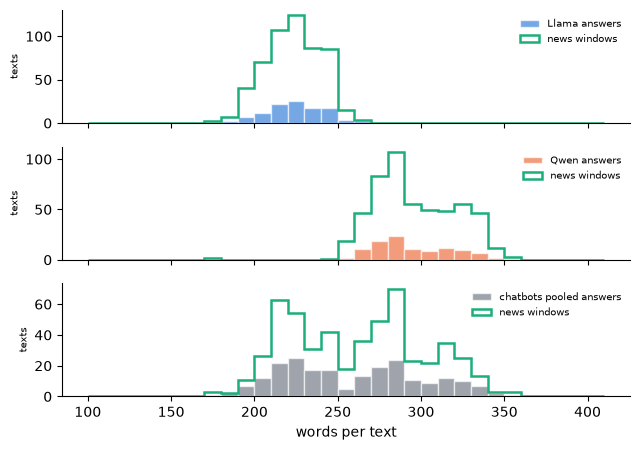

In [15]:
fig, axes = plt.subplots(3, 1, figsize=(6.5, 4.6), sharex=True); bins = np.arange(100, 420, 10)
for ax, (gname, w) in zip(axes, WIN.items()):
    a = chat if gname == "chatbots pooled" else chat[chat.group == gname]
    ax.hist(a["n_words"], bins=bins, alpha=0.65, color=COLOR.get(gname, "#6b7280"), label=f"{gname} answers", edgecolor="white")
    ax.hist(w["n_words"], bins=bins, histtype="step", color=COLOR["news"], linewidth=1.8, label="news windows")
    ax.legend(fontsize=7, frameon=False); ax.set_ylabel("texts", fontsize=7); ax.spines[["top", "right"]].set_visible(False)
axes[-1].set_xlabel("words per text"); fig.tight_layout(); fig.savefig(OUT / "h1_window_length_histograms.png", dpi=200); plt.show()

## 12. H1 robustness summary

In [16]:
summ = pd.DataFrame(SUMMARY)
summ = summ[["run", "comparison", "diff", "diff_lo", "diff_hi", "excludes_zero", "direction", "n_chatbot", "n_news"]].copy()
summ.round(4).to_csv(OUT / "h1_robustness_summary.csv", index=False)
wide = summ.assign(cell=lambda d: d["diff"].round(3).astype(str) + " [" + d["diff_lo"].round(3).astype(str) + ", " + d["diff_hi"].round(3).astype(str) + "]" + np.where(d["excludes_zero"], " *", ""))
display(wide.pivot(index="run", columns="comparison", values="cell").reindex(summ["run"].drop_duplicates()))
print("* = 95% interval excludes zero. Difference = chatbot minus news in mean rarefied entropy (K=5 unless the run says otherwise).")

comparison,Llama vs news,Qwen vs news,chatbots pooled vs news
run,,,
"main: full text, K=5","-0.004 [-0.035, 0.027]","0.058 [0.037, 0.078] *","0.027 [0.002, 0.051] *"
K=3,"-0.0 [-0.023, 0.022]","0.042 [0.027, 0.056] *","0.021 [0.003, 0.037] *"
K=8,"-0.011 [-0.048, 0.025]","0.067 [0.041, 0.091] *","0.029 [-0.0, 0.056]"
bounds: (a) excluded scored at the minimum (0),"0.005 [-0.028, 0.036]","0.066 [0.044, 0.087] *","0.035 [0.01, 0.06] *"
bounds: (b) excluded scored at the group median,"-0.004 [-0.035, 0.026]","0.058 [0.037, 0.077] *","0.027 [0.002, 0.05] *"
bounds: (c) excluded scored at the maximum,"-0.01 [-0.042, 0.02]","0.051 [0.03, 0.071] *","0.02 [-0.005, 0.044]"
pooled counts,"0.01 [-0.072, 0.043]","-0.025 [-0.072, 0.013]","-0.01 [-0.069, 0.026]"
lexicon: no governance frame,"-0.022 [-0.06, 0.016]","0.075 [0.042, 0.107] *","0.028 [-0.006, 0.061]"
lexicon: no ambiguous terms,"-0.027 [-0.076, 0.02]","0.063 [0.036, 0.088] *","0.019 [-0.017, 0.053]"


* = 95% interval excludes zero. Difference = chatbot minus news in mean rarefied entropy (K=5 unless the run says otherwise).


**Reading the robustness table.** (1) **Qwen is higher than news in every text-level run** (+0.04 to +0.10; the interval excludes zero in all of them). It is not higher in the aggregate comparison (pooled counts, below). (2) **Llama is indistinguishable from news** at full text (−0.004 [−0.035, +0.027]) and in the windows (−0.002), at K = 3 and 8 and in all bounds. It becomes higher only when each answer loses the terms in its own prompt (+0.033 [+0.007, +0.059]; chatbots only, so asymmetric, and +0.017 [−0.007, +0.042] with the symmetric version) and in the fixed 300-word cut (+0.038 [+0.005, +0.072]; at 150 words +0.039 [−0.005, +0.083]). (3) **The pooled-chatbot result is fragile**: +0.027 [+0.002, +0.051] at the main setting, but the interval includes zero at K = 8, with the upper-bound fill (c), without the governance frame, and without ambiguous terms. It excludes zero without "lawsuit" and in both prompt-echo runs. (4) **Pooled counts show no difference** (entropy about 0.91–0.94 for both groups, all three intervals include zero): across the whole corpus the frame mix is about equally spread, so the text-level gap for Qwen is a within-text effect, not a difference in the aggregate mix. (5) The **fixed cuts** give the largest gaps (+0.07 pooled), but at 150 words only 41% of news articles are scorable (at least 5 hits) against 96–99% of answers, so the news side is a selected subset; at 300 words 76%. Do not read the cuts as stronger evidence. (6) The **topic-selected windows** match the answer lengths closely (KS 0.03–0.05; 359 of 420 articles keep a window for Llama; 17–24% of windows have fewer than 5 hits and are excluded) and give the same pattern as full text.

**Overall.** H1 is **partly supported and model-dependent**: Qwen answers spread emphasis more evenly than news within a text, Llama answers do not, and the pooled claim is marginal and fragile. The text-level gaps are small (0.03–0.06 on a 0–0.9 scale).

## 13. H2: is the chatbot-minus-news gap smaller for leaning prompts?
Gap = chatbot mean rarefied entropy minus the news mean, by prompt wording. Paired contrasts by question (`question_id`): the same 18 questions appear in all three wordings, so the contrast is computed question by question and the news term cancels. **H2 predicts a smaller gap for leaning prompts, i.e. a negative contrast (leaning minus neutral).** Interval: bootstrap over questions (chatbot) and outlets (news).

In [17]:
W = ["neutral", "leaning_for", "leaning_against"]
def qw_table(df):
    t = df.groupby(["question_id", "wording"])["rar5"].mean().unstack().reindex(columns=W)
    return t

rows = []
n_mean, n_boot_means = boot_means(news["rar5"], news["cluster"], N_BOOT, SEED + 1)
for gname, sel in GROUPS.items():
    t = qw_table(sel(chat)); T = t.to_numpy(); idx = np.random.default_rng(SEED).integers(0, len(t), (N_BOOT, len(t)))
    Bq = np.stack([np.nanmean(T[idx][:, :, j], axis=1) for j in range(3)], axis=1)            # bootstrap mean per wording
    def row(label, est, boot):
        lo, hi = np.percentile(boot, [2.5, 97.5]); return {"chatbot": gname, "quantity": label, "estimate": est, "lo": lo, "hi": hi, "excludes_zero": bool(lo > 0 or hi < 0)}
    for j, w in enumerate(W):
        rows.append(row(f"gap (chatbot - news): {w}", np.nanmean(T[:, j]) - n_mean, Bq[:, j] - n_boot_means))
    rows.append(row("contrast: leaning_for - neutral", np.nanmean(T[:, 1]) - np.nanmean(T[:, 0]), Bq[:, 1] - Bq[:, 0]))
    rows.append(row("contrast: leaning_against - neutral", np.nanmean(T[:, 2]) - np.nanmean(T[:, 0]), Bq[:, 2] - Bq[:, 0]))
    lean = (Bq[:, 1] + Bq[:, 2]) / 2; lean_est = (np.nanmean(T[:, 1]) + np.nanmean(T[:, 2])) / 2
    rows.append(row("contrast: leaning (both) - neutral", lean_est - np.nanmean(T[:, 0]), lean - Bq[:, 0]))
h2 = pd.DataFrame(rows); h2["n_questions"] = 18; h2.round(4).to_csv(OUT / "h2_gap_and_contrasts.csv", index=False)
display(h2.round(4))

,chatbot,quantity,estimate,lo,hi,excludes_zero,n_questions
0,Llama,gap (chatbot - news): neutral,-0.0032,-0.0353,0.0285,False,18
1,Llama,gap (chatbot - news): leaning_for,-0.0158,-0.0605,0.0269,False,18
2,Llama,gap (chatbot - news): leaning_against,0.0079,-0.0307,0.0491,False,18
3,Llama,contrast: leaning_for - neutral,-0.0126,-0.0507,0.0259,False,18
4,Llama,contrast: leaning_against - neutral,0.0111,-0.0246,0.0473,False,18
5,Llama,contrast: leaning (both) - neutral,-0.0008,-0.0284,0.0278,False,18
6,Qwen,gap (chatbot - news): neutral,0.0593,0.0416,0.0765,True,18
7,Qwen,gap (chatbot - news): leaning_for,0.0571,0.0238,0.0866,True,18
8,Qwen,gap (chatbot - news): leaning_against,0.0572,0.0335,0.0804,True,18
9,Qwen,contrast: leaning_for - neutral,-0.0022,-0.0300,0.0227,False,18


**Reading H2.** **H2 is not supported.** No contrast excludes zero for either chatbot or pooled; the pooled estimates are −0.007 (leaning_for − neutral), +0.005 (leaning_against − neutral) and −0.001 (both leaning − neutral), all with intervals of roughly ±0.02–0.03. Qwen's gap is flat across wordings (+0.059 neutral, +0.057 for, +0.057 against, each excluding zero). Llama's gap is indistinguishable from zero in every wording (−0.003, −0.016, +0.008), so there is no gap for the wording to shrink. With 18 questions the intervals are wide: this is a failure to find an effect, not evidence of no effect.

**Stance check on the lexicon.** H2 compares prompts that lean for or against regulation, so a lexicon that contained stance words (words that mean "good" or "bad" for regulation) would make H2 partly circular. Two checks: (1) every term was read for evaluative meaning (listed below with the verdict); (2) a data check: terms whose hit rate in `leaning_for` answers differs strongly from `leaning_against` answers (sum over both chatbots, full text).

In [18]:
w = chat.set_index("text_id")["wording"]
tt = term[term.source == "chatbot"].copy(); tt["wording"] = tt["text_id"].map(w)
nF, nA = int((chat.wording == "leaning_for").sum()), int((chat.wording == "leaning_against").sum())
hits_w = tt.pivot_table(index="term", columns="wording", values="n", aggfunc="sum", fill_value=0).reindex(columns=W, fill_value=0)
st = hits_w.assign(frame=[LEX.owner[t] for t in hits_w.index])
st["per_answer_for"] = st["leaning_for"] / nF; st["per_answer_against"] = st["leaning_against"] / nA
st["log2_ratio_for_vs_against"] = np.log2((st["per_answer_for"] + 0.05) / (st["per_answer_against"] + 0.05))
st["total_hits"] = st[W].sum(axis=1)
flag = st[(st.total_hits >= 10) & (st.log2_ratio_for_vs_against.abs() >= 1)].sort_values("log2_ratio_for_vs_against")
st.round(3).to_csv(OUT / "h2_stance_term_check.csv"); print(len(st), "terms fire in chatbot answers;", len(flag), "have >= 10 hits and a for/against rate ratio of 2x or more:")
display(flag[["frame", "leaning_for", "leaning_against", "neutral", "log2_ratio_for_vs_against"]].round(2))
# all lexicon terms, to read for evaluative words
for f in FRAMES: print(f"\n{f}:", ", ".join(sorted(t for t, o in LEX.owner.items() if o == f)))

183 terms fire in chatbot answers; 15 have >= 10 hits and a for/against rate ratio of 2x or more:


wording,frame,leaning_for,leaning_against,neutral,log2_ratio_for_vs_against
term,,,,,
research and development,innovation_opportunity,2,12,2,-1.48
restriction,regulation_governance,4,17,16,-1.44
dominance,economy_labour,2,9,2,-1.17
breakthrough,innovation_opportunity,1,6,4,-1.06
surveillance,rights_privacy,11,3,7,1.15
harm,risk_safety,45,18,37,1.17
vulnerability,risk_safety,10,2,6,1.28
safeguard,risk_safety,25,7,23,1.43
integrity,misinformation_integrity,9,1,12,1.45



innovation_opportunity: advancement, beneficial, benefit, breakthrough, creative, creativity, cut edge, discovery, experiment, experimentation, flourish, innovate, innovation, innovative, invent, invention, new product, opportunity, pioneer, potential, progress, research and development, start up, startup, thrive, transform, transformative, unlock

risk_safety: accident, adverse, catastrophic, cyberattack, cybersecurity, danger, dangerous, existential, failure, fatal, guardrail, harm, harmful, hazard, high stake, injury, malfunction, misuse, mitigate, mitigation, reliability, risk, robustness, safe, safeguard, safety, security, threat, unintended, unpredictable, unsafe, vulnerability, weapon

regulation_governance: accountability, accountable, approval, audit, authority, certification, compliance, comply, disclosure, enforce, enforcement, framework, governance, harmonize, human intervention, international cooperation, jurisdiction, lawmaker, lawsuit, legislate, legislation, legislativ

**Reading the stance check.** *By reading all 206 terms:* no term states a position on regulation (the pejorative ones, red tape and bureaucracy, were removed in v1.1). There are valence words that describe AI outcomes, not regulation: beneficial, benefit, flourish, thrive, cutting edge (innovation, positive) and harmful, dangerous, unsafe, fatal, catastrophic (risk, negative). *By the data:* Of the 183 terms that fire, 15 have at least 10 hits and occur at least twice as often (per answer) in one stance's answers than in the other. More in `leaning_for` answers: harm, safeguard, mitigate, vulnerability, catastrophic, deepfake, integrity, surveillance, dignity, human right, profit (14 vs 1). More in `leaning_against` answers: research and development, restriction, dominance, breakthrough. These follow the content of the argument (why rules help, why they hurt), not an evaluation word, and H2 is about evenness, not which frame leads, but frame identity and stance are tied, so a change in entropy by wording could come from the arguments themselves. State this as a limitation of H2.

## 14. H3 (exploratory): Jensen-Shannon divergence between chatbot and news frame mixes
Frame distribution = share of all frame hits in a group (full text; jurisdiction terms are scored separately and are not in these counts: checked in section 1). JSD with base-2 logarithm (0 = identical, 1 = no overlap). Interval: bootstrap over questions (chatbot) and outlets (news region), 5,000 draws. **This is exploratory.** Sample sizes: US 133, Other 104, UK 101, EU 82 articles; the **EU and UK comparisons are the weakest** (fewest articles, fewest outlets, and the narrowest English-language outlet base). The noise floor column is the mean JSD between two random halves of the same group's clusters; JSD between small samples is biased upwards, so compare each divergence with the floor of its own region.

In [19]:
def jsd(p, q):
    p, q = np.asarray(p, float), np.asarray(q, float); p, q = p / p.sum(), q / q.sum(); m = (p + q) / 2
    kl = lambda a, b: np.sum(np.where(a > 0, a * np.log2(a / np.where(b > 0, b, 1)), 0.0))
    return 0.5 * kl(p, m) + 0.5 * kl(q, m)

def cluster_sums(M, clusters):
    return pd.DataFrame(M).groupby(np.asarray(clusters)).sum().to_numpy()

def boot_dist(CS, n=N_BOOT, seed=SEED):
    r = np.random.default_rng(seed); return CS[r.integers(0, len(CS), (n, len(CS)))].sum(axis=1)       # n x frames

def floor(CS, reps=500, seed=SEED):
    r = np.random.default_rng(seed); v = []
    for _ in range(reps):
        p = r.permutation(len(CS)); h = len(CS) // 2; v.append(jsd(CS[p[:h]].sum(axis=0), CS[p[h:]].sum(axis=0)))
    return float(np.mean(v))

CS_chat = {g: cluster_sums(M_chat[sel(chat).index], sel(chat)["cluster"]) for g, sel in GROUPS.items()}
CS_news = {r: cluster_sums(M_news[(news.region == r).to_numpy()], news.loc[news.region == r, "cluster"]) for r in ["US", "UK", "EU", "Other"]}
rows, drawn = [], {}
for g, A in CS_chat.items():
    ba = boot_dist(A, seed=SEED)
    for r, B in CS_news.items():
        bb = boot_dist(B, seed=SEED + 1); d = np.array([jsd(x, y) for x, y in zip(ba, bb)]); lo, hi = np.percentile(d, [2.5, 97.5]); drawn[(g, r)] = d
        rows.append({"chatbot": g, "news_region": r, "jsd": jsd(A.sum(axis=0), B.sum(axis=0)), "lo": lo, "hi": hi,
                     "n_articles": int((news.region == r).sum()), "n_outlets": B.shape[0], "news_hits": int(B.sum()),
                     "noise_floor_news_halves": floor(B), "noise_floor_chatbot_halves": floor(A)})
h3 = pd.DataFrame(rows); h3["closest_region_for_this_chatbot"] = h3.groupby("chatbot")["jsd"].transform(lambda s: s == s.min())
h3.round(4).to_csv(OUT / "h3_jsd_chatbot_vs_news_regions.csv", index=False)
display(h3.round(4))
print("Pairwise JSD among all six frame distributions (point estimates, for scale):")
allg = {**{g: A.sum(axis=0) for g, A in CS_chat.items() if g != "chatbots pooled"}, **{f"news {r}": B.sum(axis=0) for r, B in CS_news.items()}}
pair = pd.DataFrame({a: {b: jsd(allg[a], allg[b]) for b in allg} for a in allg}).round(4); pair.to_csv(OUT / "h3_pairwise_jsd.csv"); display(pair)

# Is a chatbot closer to one region than another? Compare the divergences on the SAME chatbot bootstrap draws (paired), news draws independent.
point = {(r["chatbot"], r["news_region"]): r["jsd"] for r in rows}; prs = []
regs = ["US", "UK", "EU", "Other"]
for g in CS_chat:
    for i, r1 in enumerate(regs):
        for r2 in regs[i + 1:]:
            dd = drawn[(g, r1)] - drawn[(g, r2)]; lo, hi = np.percentile(dd, [2.5, 97.5]); est = point[(g, r1)] - point[(g, r2)]
            prs.append({"chatbot": g, "comparison": f"JSD({r1}) - JSD({r2})", "estimate": est, "lo": lo, "hi": hi, "boot_mean": float(dd.mean()),
                        "excludes_zero": bool(lo > 0 or hi < 0), "closer_to": r1 if est < 0 else r2})
h3_diff = pd.DataFrame(prs); h3_diff.round(4).to_csv(OUT / "h3_region_differences.csv", index=False)
print("Is the chatbot closer to one region than to another? (negative = closer to the first region)"); display(h3_diff.round(4))

,chatbot,news_region,jsd,lo,hi,n_articles,n_outlets,news_hits,noise_floor_news_halves,noise_floor_chatbot_halves,closest_region_for_this_chatbot
0,Llama,US,0.0298,0.0180,0.0829,133,108,4227,0.0080,0.0505,False
1,Llama,UK,0.0136,0.0090,0.0591,101,87,2915,0.0087,0.0505,True
2,Llama,EU,0.0210,0.0136,0.0745,82,76,2675,0.0133,0.0505,False
3,Llama,Other,0.0308,0.0155,0.0914,104,75,2876,0.0119,0.0505,False
4,Qwen,US,0.0324,0.0184,0.0687,133,108,4227,0.0080,0.0214,False
5,Qwen,UK,0.0169,0.0084,0.0475,101,87,2915,0.0087,0.0214,True
6,Qwen,EU,0.0220,0.0123,0.0566,82,76,2675,0.0133,0.0214,False
7,Qwen,Other,0.0338,0.0158,0.0784,104,75,2876,0.0119,0.0214,False
8,chatbots pooled,US,0.0299,0.0168,0.0702,133,108,4227,0.0080,0.0295,False
9,chatbots pooled,UK,0.0141,0.0074,0.0483,101,87,2915,0.0087,0.0295,True


Pairwise JSD among all six frame distributions (point estimates, for scale):


,Llama,Qwen,news US,news UK,news EU,news Other
Llama,0.0000,0.0072,0.0298,0.0136,0.0210,0.0308
Qwen,0.0072,0.0000,0.0324,0.0169,0.0220,0.0338
news US,0.0298,0.0324,0.0000,0.0039,0.0136,0.0027
news UK,0.0136,0.0169,0.0039,0.0000,0.0061,0.0068
news EU,0.0210,0.0220,0.0136,0.0061,0.0000,0.0219
news Other,0.0308,0.0338,0.0027,0.0068,0.0219,0.0000


Is the chatbot closer to one region than to another? (negative = closer to the first region)


,chatbot,comparison,estimate,lo,hi,boot_mean,excludes_zero,closer_to
0,Llama,JSD(US) - JSD(UK),0.0163,-0.0043,0.0401,0.0160,False,UK
1,Llama,JSD(US) - JSD(EU),0.0088,-0.0293,0.0429,0.0071,False,EU
2,Llama,JSD(US) - JSD(Other),-0.0010,-0.0301,0.0247,-0.0011,False,US
3,Llama,JSD(UK) - JSD(EU),-0.0074,-0.0380,0.0186,-0.0089,False,UK
4,Llama,JSD(UK) - JSD(Other),-0.0172,-0.0500,0.0088,-0.0171,False,UK
5,Llama,JSD(EU) - JSD(Other),-0.0098,-0.0532,0.0365,-0.0082,False,EU
6,Qwen,JSD(US) - JSD(UK),0.0155,-0.0041,0.0366,0.0152,False,UK
7,Qwen,JSD(US) - JSD(EU),0.0104,-0.0204,0.0384,0.0088,False,EU
8,Qwen,JSD(US) - JSD(Other),-0.0014,-0.0304,0.0233,-0.0018,False,US
9,Qwen,JSD(UK) - JSD(EU),-0.0051,-0.0310,0.0174,-0.0064,False,UK


**Reading H3 (exploratory).** Point estimates put the UK closest to both chatbots (JSD 0.014 Llama, 0.017 Qwen, 0.014 pooled) and the US and Other furthest (about 0.030–0.034), EU between (0.020–0.022). The paired differences between regions on the same chatbot draws all have intervals that include zero (for example JSD(US) − JSD(UK) = +0.016 [−0.003, +0.038] for pooled chatbots), so **no region is reliably closer than another**. Three cautions: (1) the percentile intervals sit above the point estimates (JSD is biased upwards when clusters are resampled, especially with 18 question clusters), so read them as a plausible range, not a symmetric interval; (2) the noise floor for two random halves of the chatbots' own questions is large next to the divergences: Llama 0.051 exceeds all four of its divergences (0.014–0.031), pooled 0.030 equals the US and Other values, and Qwen 0.021 is below its US and Other values (0.032, 0.034) but above its UK value (0.017). The 18-question set alone moves the mix about as much as the choice of region, which limits what H3 can show; (3) the news regions are close to each other (US–Other 0.003, US–UK 0.004) except EU (EU–Other 0.022, EU–US 0.014), which is the smallest sample (82 articles, 76 outlets). EU and UK are the weakest comparisons.

## 15. Frame mix per prompt topic, next to the pooled entropy
The prompt set is balanced by design (3 questions per `topic_frame`), so a pooled frame distribution looks spread out partly because the prompts ask about all six topics. The table shows the mix within each topic (share of hits per frame) and the mean rarefied entropy within the topic, so the by-design balance is visible.

In [20]:
rows = []
for gname, sel in GROUPS.items():
    d = sel(chat)
    for tf, g in list(d.groupby("topic_frame")) + [("ALL TOPICS (pooled)", d)]:
        s = g[HC].sum(); s = s / s.sum()
        rows.append({"chatbot": gname, "topic_frame": tf, "n_answers": len(g), **{f.replace("hits_", "share_"): v for f, v in s.items()},
                     "mean_rarefied_entropy_k5": g["rar5"].mean(), "pooled_entropy_of_mix": entropy(g[HC].sum().to_numpy(), 1)})
topic_mix = pd.DataFrame(rows).round(3); topic_mix.to_csv(OUT / "frame_mix_by_topic_with_entropy.csv", index=False); display(topic_mix)

,chatbot,topic_frame,n_answers,share_innovation_opportunity,share_risk_safety,share_regulation_governance,share_rights_privacy,share_economy_labour,share_misinformation_integrity,mean_rarefied_entropy_k5,pooled_entropy_of_mix
0,Llama,economy_labour,18,0.233,0.103,0.155,0.011,0.497,0.000,0.471,0.704
1,Llama,governance,18,0.232,0.199,0.442,0.034,0.090,0.004,0.479,0.766
2,Llama,innovation,18,0.344,0.190,0.322,0.037,0.089,0.018,0.515,0.814
3,Llama,misinformation,18,0.146,0.131,0.261,0.015,0.020,0.427,0.529,0.783
4,Llama,rights_privacy,18,0.111,0.177,0.155,0.498,0.026,0.033,0.529,0.778
5,Llama,risk_safety,18,0.187,0.555,0.201,0.010,0.043,0.003,0.437,0.650
6,Llama,ALL TOPICS (pooled),108,0.216,0.229,0.252,0.097,0.146,0.060,0.493,0.944
7,Qwen,economy_labour,18,0.205,0.183,0.207,0.014,0.386,0.006,0.539,0.792
8,Qwen,governance,18,0.125,0.301,0.404,0.037,0.113,0.020,0.545,0.800
9,Qwen,innovation,18,0.237,0.274,0.317,0.036,0.118,0.017,0.578,0.839


**Reading the table.** In 4 of the 6 topics the question's own frame has the largest share (economy/labour 0.43, risk/safety 0.46, rights/privacy 0.38, misinformation 0.33; governance questions give governance 0.42). In the innovation topic governance (0.32) outweighs innovation (0.28). Within-topic mean rarefied entropy is 0.48–0.56. The pooled mix (all topics together) has a plain entropy of 0.925 against 0.73–0.85 within each topic: the pooled figure looks spread out partly because the prompt set asks about all six topics by design.

## 16. Frame composition (exploratory): which frames differ?
H1 and H2 are about *evenness*. This section asks a different question: **how much of each text's emphasis goes to each frame**. For every text (full text, every text with at least one hit) the share of its hits in each frame; the table is the mean of those shares per group, with a 95% cluster-bootstrap interval (`question_id` for chatbots, `outlet` for news; the same cluster draws are used for all six frames, so the frames are resampled jointly). The second table is the chatbot-minus-news difference per frame against all news.

**Exploratory.** Six frames times several groups, no correction for multiple comparisons; the shares of one text sum to 1, so the frames are not independent. Governance is partly present **by design** (the prompts ask about regulation, and 3 of the 18 questions are about governance), and the on-topic rule used to build the corpus shares words with the governance lexicon (see `RESULTS.md`); treat the governance row with particular care.

In [21]:
SHARE_COLS = [f.replace("hits_", "share_") for f in HC]
def shares(d):
    ok = d["hits_total"] > 0
    return d[ok][HC].div(d[ok]["hits_total"], axis=0).set_axis(FRAMES, axis=1), d[ok]["cluster"]

comp_groups = {"Llama": chat[chat.group == "Llama"], "Qwen": chat[chat.group == "Qwen"], "chatbots pooled": chat, "news (all)": news,
               **{f"news | {r}": news[news.region == r] for r in ["US", "UK", "EU", "Other"]}}
rows, boots = [], {}
for gname, d in comp_groups.items():
    S, cl = shares(d)
    for f in FRAMES:
        m, b = boot_means(S[f].to_numpy(), cl.to_numpy(), N_BOOT, SEED if not gname.startswith("news") else SEED + 1)
        boots[(gname, f)] = b; lo, hi = np.percentile(b, [2.5, 97.5])
        rows.append({"group": gname, "frame": f, "n_texts": len(S), "n_clusters": cl.nunique(), "mean_share": m, "lo": lo, "hi": hi})
comp = pd.DataFrame(rows); comp.round(4).to_csv(OUT / "composition_by_frame.csv", index=False)
display(comp.pivot(index="frame", columns="group", values="mean_share").reindex(FRAMES)[list(comp_groups)].round(3))

drows = []
for g in ["Llama", "Qwen", "chatbots pooled"]:
    for f in FRAMES:
        est = comp[(comp.group == g) & (comp.frame == f)]["mean_share"].iloc[0] - comp[(comp.group == "news (all)") & (comp.frame == f)]["mean_share"].iloc[0]
        d = boots[(g, f)] - boots[("news (all)", f)]; lo, hi = np.percentile(d, [2.5, 97.5])
        drows.append({"chatbot": g, "frame": f, "diff_share": est, "lo": lo, "hi": hi, "excludes_zero": bool(lo > 0 or hi < 0)})
comp_diff = pd.DataFrame(drows); comp_diff.round(4).to_csv(OUT / "composition_differences_vs_news.csv", index=False)
display(comp_diff.pivot(index="frame", columns="chatbot", values="diff_share").reindex(FRAMES).round(3))
print("difference excludes zero (chatbot minus all news):")
display(comp_diff.pivot(index="frame", columns="chatbot", values="excludes_zero").reindex(FRAMES))

group,Llama,Qwen,chatbots pooled,news (all),news | US,news | UK,news | EU,news | Other
frame,,,,,,,,
innovation_opportunity,0.211,0.168,0.190,0.121,0.117,0.135,0.109,0.122
risk_safety,0.221,0.251,0.236,0.253,0.257,0.251,0.230,0.267
regulation_governance,0.261,0.314,0.287,0.227,0.212,0.217,0.254,0.236
rights_privacy,0.099,0.075,0.087,0.096,0.099,0.100,0.122,0.069
economy_labour,0.127,0.128,0.128,0.241,0.268,0.225,0.205,0.252
misinformation_integrity,0.081,0.063,0.072,0.062,0.048,0.072,0.080,0.054


chatbot,Llama,Qwen,chatbots pooled
frame,,,
innovation_opportunity,0.090,0.048,0.069
risk_safety,-0.032,-0.002,-0.017
regulation_governance,0.033,0.087,0.060
rights_privacy,0.003,-0.021,-0.009
economy_labour,-0.114,-0.114,-0.114
misinformation_integrity,0.019,0.001,0.010


difference excludes zero (chatbot minus all news):


chatbot,Llama,Qwen,chatbots pooled
frame,,,
innovation_opportunity,True,True,True
risk_safety,False,False,False
regulation_governance,False,True,True
rights_privacy,False,False,False
economy_labour,True,True,True
misinformation_integrity,False,False,False


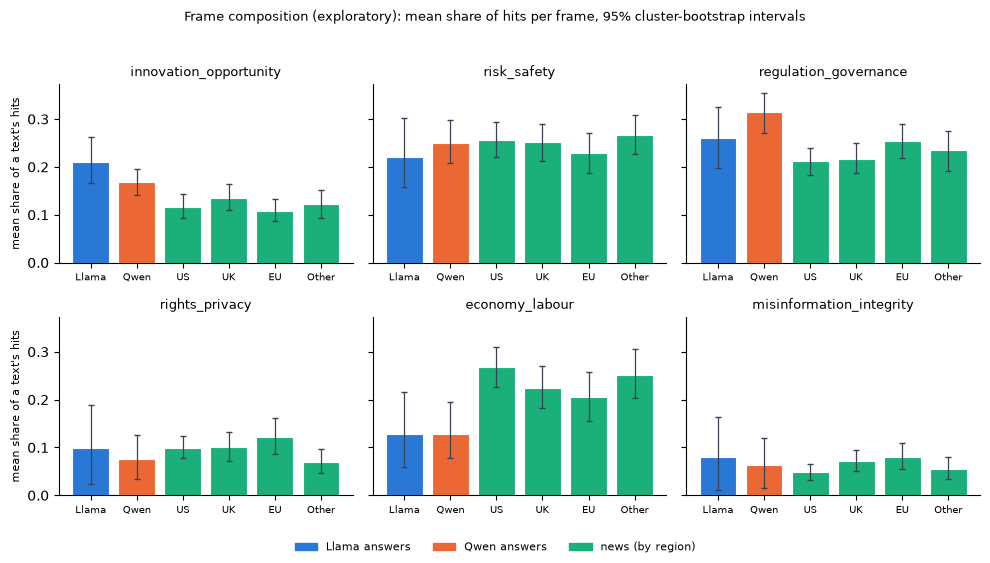

In [22]:
GROUP_ORDER = ["Llama", "Qwen", "news | US", "news | UK", "news | EU", "news | Other"]
GCOL = {"Llama": COLOR["Llama"], "Qwen": COLOR["Qwen"], **{g: COLOR["news"] for g in GROUP_ORDER[2:]}}
fig, axes = plt.subplots(2, 3, figsize=(10, 5.6), sharey=True)
for ax, f in zip(axes.ravel(), FRAMES):
    sub = comp[comp.frame == f].set_index("group").loc[GROUP_ORDER]
    x = np.arange(len(sub)); err = np.vstack([sub["mean_share"] - sub["lo"], sub["hi"] - sub["mean_share"]])
    ax.bar(x, sub["mean_share"], color=[GCOL[g] for g in sub.index], edgecolor="white", linewidth=0.8, yerr=err, ecolor="#374151", capsize=2, error_kw={"linewidth": 0.9})
    ax.set_xticks(x); ax.set_xticklabels([g.replace("news | ", "") for g in sub.index], fontsize=7.5, rotation=0)
    ax.set_title(f, fontsize=9); ax.spines[["top", "right"]].set_visible(False)
for ax in axes[:, 0]: ax.set_ylabel("mean share of a text's hits", fontsize=8)
from matplotlib.patches import Patch
fig.legend(handles=[Patch(color=COLOR["Llama"], label="Llama answers"), Patch(color=COLOR["Qwen"], label="Qwen answers"), Patch(color=COLOR["news"], label="news (by region)")],
           loc="lower center", ncol=3, frameon=False, fontsize=8)
fig.suptitle("Frame composition (exploratory): mean share of hits per frame, 95% cluster-bootstrap intervals", fontsize=9.5)
fig.tight_layout(rect=(0, 0.05, 1, 0.96)); fig.savefig(OUT / "composition_by_frame.png", dpi=200); plt.show()

**Reading the composition (exploratory).** Both chatbots put a **larger share of their hits in innovation/opportunity** than news (+0.090 Llama, +0.048 Qwen, +0.069 pooled) and a **smaller share in economy/labour** (−0.114 in all three); all of these intervals exclude zero. Governance is higher for Qwen (+0.087) and for the pooled chatbots (+0.060) but not distinguishable for Llama (+0.034 [−0.031, +0.100]). Risk/safety, rights/privacy and misinformation do not differ (all intervals include zero, about ±0.05–0.10). News regions differ little and their intervals overlap: economy/labour is 0.268 (US), 0.252 (Other), 0.225 (UK), 0.205 (EU); EU is highest in governance (0.254) and rights (0.122).

**Caveats.** (1) **Governance is partly present by design**: every prompt asks what governments should do about AI, 3 of the 18 questions are about governance, and the lexicon's governance terms (regulator, oversight, standard, ...) appear in the prompts. (2) **The on-topic filter shares words with the governance lexicon**: 9 of its 39 terms (regulator, regulatory, oversight, legislation, legislate, legislature, governance, lawmaker, legislative) contain words that the corpus on-topic rule counts, and they supply 34% of news governance hits against 24% of chatbot hits; articles were chosen for at least 2 regulation words, so part of the news governance share is built in by selection. (3) Exploratory: 12 comparisons without correction, and the shares of one text sum to 1, so a higher share in one frame lowers the others. (4) The chatbot intervals rest on 18 question clusters.

### Composition again without the filter-overlap terms
The on-topic rule that built the news corpus counts words such as *regulat\**, *legislat\**, *oversight*, *governance* and *lawmaker*. Governance lexicon terms that contain such a word are removed here, from **both** groups, and every share is recomputed (the other frames' shares rise a little as the denominator shrinks). The question is whether the governance difference between chatbots and news survives when the part of the news governance share that the filter selected for is taken out.

In [23]:
OVERLAP = sorted(t for t, f in LEX.owner.items() if f == "regulation_governance" and REG_WORDS.search(t))
assert len(OVERLAP) == 9, OVERLAP
print(len(OVERLAP), "governance terms contain a word the on-topic rule counts:", ", ".join(OVERLAP))

def comp_variant(drop):
    Mc, Mn = mat(chat, "chatbot", FRAMES, drop), mat(news, "news", FRAMES, drop); rows_, bt = [], {}
    for gname, d in comp_groups.items():
        cnt = (Mn if gname.startswith("news") else Mc)[d.index.to_numpy()]; tot = cnt.sum(axis=1); ok = tot > 0
        S = pd.DataFrame(cnt[ok] / tot[ok][:, None], columns=FRAMES); cl = d["cluster"].to_numpy()[ok]
        for f in FRAMES:
            m, b = boot_means(S[f].to_numpy(), cl, N_BOOT, SEED if not gname.startswith("news") else SEED + 1); bt[(gname, f)] = b
            lo, hi = np.percentile(b, [2.5, 97.5]); rows_.append({"group": gname, "frame": f, "n_texts": int(ok.sum()), "n_clusters": len(set(cl)), "mean_share": m, "lo": lo, "hi": hi})
    c = pd.DataFrame(rows_); dr = []
    for g in ["Llama", "Qwen", "chatbots pooled"]:
        for f in FRAMES:
            est = c[(c.group == g) & (c.frame == f)]["mean_share"].iloc[0] - c[(c.group == "news (all)") & (c.frame == f)]["mean_share"].iloc[0]
            dd = bt[(g, f)] - bt[("news (all)", f)]; lo, hi = np.percentile(dd, [2.5, 97.5]); dr.append({"chatbot": g, "frame": f, "diff_share": est, "lo": lo, "hi": hi, "excludes_zero": bool(lo > 0 or hi < 0)})
    return c, pd.DataFrame(dr)

c0, d0 = comp_variant(frozenset())
assert np.allclose(c0["mean_share"], comp["mean_share"]), "the all-terms variant must reproduce the main composition table"
c1, d1 = comp_variant(frozenset(OVERLAP))
c1.round(4).to_csv(OUT / "composition_by_frame_no_filter_overlap.csv", index=False); d1.round(4).to_csv(OUT / "composition_differences_no_filter_overlap.csv", index=False)

rows_ = []
for g in ["Llama", "Qwen", "chatbots pooled"]:
    a, b = d0[(d0.chatbot == g) & (d0.frame == "regulation_governance")].iloc[0], d1[(d1.chatbot == g) & (d1.frame == "regulation_governance")].iloc[0]
    share = lambda c, grp: c[(c.group == grp) & (c.frame == "regulation_governance")]["mean_share"].iloc[0]
    rows_.append({"chatbot": g, "gov_share_chatbot_all_terms": share(c0, g), "gov_share_news_all_terms": share(c0, "news (all)"),
                  "gov_diff_all_terms": a["diff_share"], "lo_all": a["lo"], "hi_all": a["hi"], "excludes_zero_all": a["excludes_zero"],
                  "gov_share_chatbot_without_overlap": share(c1, g), "gov_share_news_without_overlap": share(c1, "news (all)"),
                  "gov_diff_without_overlap": b["diff_share"], "lo_without": b["lo"], "hi_without": b["hi"], "excludes_zero_without": b["excludes_zero"]})
gov_effect = pd.DataFrame(rows_); gov_effect.round(4).to_csv(OUT / "composition_governance_effect.csv", index=False)
display(gov_effect.round(3).T)
print("all six frames, chatbot minus news, without the overlap terms (* = interval excludes zero):")
x = d1.assign(cell=lambda d: d["diff_share"].map("{:+.3f}".format) + " [" + d["lo"].map("{:+.3f}".format) + ", " + d["hi"].map("{:+.3f}".format) + "]" + np.where(d["excludes_zero"], " *", ""))
display(x.pivot(index="frame", columns="chatbot", values="cell").reindex(FRAMES))

9 governance terms contain a word the on-topic rule counts: governance, lawmaker, legislate, legislation, legislative, legislature, oversight, regulator, regulatory


,0,1,2
chatbot,Llama,Qwen,chatbots pooled
gov_share_chatbot_all_terms,0.261,0.314,0.287
gov_share_news_all_terms,0.227,0.227,0.227
gov_diff_all_terms,0.033,0.087,0.06
lo_all,-0.031,0.04,0.006
hi_all,0.1,0.131,0.114
excludes_zero_all,False,True,True
gov_share_chatbot_without_overlap,0.226,0.254,0.24
gov_share_news_without_overlap,0.161,0.161,0.161
gov_diff_without_overlap,0.065,0.093,0.079


all six frames, chatbot minus news, without the overlap terms (* = interval excludes zero):


chatbot,Llama,Qwen,chatbots pooled
frame,,,
innovation_opportunity,"+0.095 [+0.042, +0.153] *","+0.053 [+0.020, +0.085] *","+0.074 [+0.034, +0.116] *"
risk_safety,"-0.046 [-0.116, +0.038]","-0.002 [-0.055, +0.053]","-0.024 [-0.083, +0.042]"
regulation_governance,"+0.065 [+0.010, +0.119] *","+0.093 [+0.049, +0.133] *","+0.079 [+0.032, +0.122] *"
rights_privacy,"-0.003 [-0.078, +0.090]","-0.023 [-0.069, +0.033]","-0.013 [-0.073, +0.061]"
economy_labour,"-0.125 [-0.201, -0.030] *","-0.121 [-0.182, -0.046] *","-0.123 [-0.191, -0.039] *"
misinformation_integrity,"+0.014 [-0.053, +0.096]","-0.000 [-0.049, +0.059]","+0.007 [-0.050, +0.076]"


**Effect of removing the filter-overlap terms.** The 9 terms are regulator, regulatory, oversight, legislation, legislate, legislature, governance, lawmaker and legislative. Without them the governance share falls in both groups, more in news (0.227 → 0.161) than in the chatbots (0.288 → 0.240 pooled), so the chatbot-minus-news governance difference **grows**: +0.060 [+0.006, +0.114] → **+0.079 [+0.032, +0.122]** pooled; Qwen +0.087 → +0.093; Llama +0.034 [−0.031, +0.100] → +0.065 [+0.010, +0.119], which now excludes zero. The filter therefore **inflates the news governance share and partly masks the chatbot-higher difference**; it does not produce the difference. The other frames barely move (innovation +0.074, economy/labour −0.123 pooled). This check does not touch the other caveat: governance is partly present by design in the prompts, and removing the 9 terms also removes the core of what the governance frame measures (regulator, oversight), so the remaining governance score is a narrower construct.

## 17. Self-test on label-shuffled data
The comparison function is run once with the group labels permuted (answers and articles swapped between sides). The numbers are noise and are never saved; the point is that the code returns a sensible table and that a label-free comparison shows no systematic gap.

In [24]:
pool = pd.concat([chat[["rar5", "cluster"]].assign(g="c"), news[["rar5", "cluster"]].assign(g="n")], ignore_index=True)
gaps = []
for s in range(20):
    p = pool.sample(frac=1, random_state=s).reset_index(drop=True); a, b = p.iloc[:len(chat)], p.iloc[len(chat):]
    r = compare(a["rar5"].to_numpy(float), a["cluster"].to_numpy(), b["rar5"].to_numpy(float), b["cluster"].to_numpy(), n_boot=300); gaps.append(r["diff"])
print("20 shuffles: mean gap", round(float(np.mean(gaps)), 4), "| mean |gap|", round(float(np.mean(np.abs(gaps))), 4), "(compare with the real gap in section 7)")

20 shuffles: mean gap -0.0 | mean |gap| 0.0053 (compare with the real gap in section 7)


## Limits to state in the report
- **Rarefaction fixes estimator bias, not real diversity.** Full-text news is about four times longer than a chatbot answer; a longer article can genuinely cover more frames. This works against H1.
- Rarefaction does not fix *which* terms are common: news and chatbot hits come from different words (the stance and echo checks in notebook 03 and section 13 look at this).
- At K = 5 the maximum entropy is 0.898 (1.0 without the governance frame); never compare across different K.
- 18 questions give 18 chatbot clusters, so chatbot intervals are wide and the bootstrap has few clusters to draw from.
- The corpus is 420 articles after the slug pre-filter (articles that name AI in the URL), frozen at that size; EU (82) and UK (101) are small.
- The lexicon was edited (v1.2) after hit counts in both corpora had been seen, before any H1–H3 test; the "no lawsuit" and variant runs are there to show whether any result depends on those edits.